## Первым делом будем подготавливать данные к анализу: загрузка, исследование строк и выбор выгружаемых

In [7]:
from datasets import load_dataset as ld

dataset = ld("irlspbru/RFSD", split="train", streaming =True)

print(dataset)

IterableDataset({
    features: ['inn', 'eligible', 'exemption_criteria', 'filed', 'financial', 'simplified', 'line_1100', 'line_1105', 'line_1110', 'line_1120', 'line_1130', 'line_1140', 'line_1150', 'line_1160', 'line_1170', 'line_1180', 'line_1190', 'line_1200', 'line_1210', 'line_1215', 'line_1220', 'line_1230', 'line_1240', 'line_1250', 'line_1260', 'line_1300', 'line_1310', 'line_1320', 'line_1330', 'line_1340', 'line_1350', 'line_1360', 'line_1370', 'line_1400', 'line_1410', 'line_1420', 'line_1430', 'line_1450', 'line_1500', 'line_1510', 'line_1520', 'line_1530', 'line_1540', 'line_1550', 'line_1600', 'line_1700', 'line_2100', 'line_2110', 'line_2120', 'line_2200', 'line_2210', 'line_2220', 'line_2300', 'line_2310', 'line_2320', 'line_2330', 'line_2340', 'line_2350', 'line_2400', 'line_2410', 'line_2411', 'line_2412', 'line_2420', 'line_2421', 'line_2430', 'line_2450', 'line_2460', 'line_2500', 'line_2510', 'line_2520', 'line_2530', 'line_2900', 'line_2910', 'line_3100', 'line_

In [6]:
row = next(iter(dataset))
for key, value in row.items():
    if not key.startswith("line_"):
        print(f"{key}: {value}")

inn: 4217064430
eligible: 1.0
exemption_criteria: none
filed: 0.0
financial: 0.0
simplified: None
totals_adjustment: None
ogrn: 1044217007526
creation_date: 2004-04-26
dissolution_date: 2011-03-25
age: 7.0
okved: 46
okved_section: G
okpo: None
okopf: 12300
okogu: None
okfc: None
oktmo: None
region: kemerovo
region_taxcode: 4200
articulated: None
outlier: 0.0
lon: None
lat: None
geocoding_quality: None
imputed: 0.0


In [10]:

financial_columns = [ col for col in dataset.features
    if col.startswith("line_") ]

print("Количество финансовых колонок:", len(financial_columns))
print(financial_columns[:60])

Количество финансовых колонок: 197
['line_1100', 'line_1105', 'line_1110', 'line_1120', 'line_1130', 'line_1140', 'line_1150', 'line_1160', 'line_1170', 'line_1180', 'line_1190', 'line_1200', 'line_1210', 'line_1215', 'line_1220', 'line_1230', 'line_1240', 'line_1250', 'line_1260', 'line_1300', 'line_1310', 'line_1320', 'line_1330', 'line_1340', 'line_1350', 'line_1360', 'line_1370', 'line_1400', 'line_1410', 'line_1420', 'line_1430', 'line_1450', 'line_1500', 'line_1510', 'line_1520', 'line_1530', 'line_1540', 'line_1550', 'line_1600', 'line_1700', 'line_2100', 'line_2110', 'line_2120', 'line_2200', 'line_2210', 'line_2220', 'line_2300', 'line_2310', 'line_2320', 'line_2330', 'line_2340', 'line_2350', 'line_2400', 'line_2410', 'line_2411', 'line_2412', 'line_2420', 'line_2421', 'line_2430', 'line_2450']


## Поскольку сами названия компаний и их реквизиты нам мало о чем скажут в смысле анализа и корреляции, будем исследовать их финансовые показатели

In [9]:

import pandas as pd

url = "https://raw.githubusercontent.com/irlcode/RFSD/main/aux_data/descriptive_names_dict.csv"

names = pd.read_csv(url)

print(names[names["original"].isin(financial_columns[:60])].to_string(index=False))

 original                           descriptive
line_1100                   B_noncurrent_assets
line_1105                            B_goodwill
line_1110                   B_intangible_assets
line_1120                B_research_development
line_1130              B_intangible_exploration
line_1140                B_tangible_exploration
line_1150                        B_fixed_assets
line_1160                     B_tangible_invest
line_1170                          B_fin_invest
line_1180                      B_def_tax_assets
line_1190             B_other_noncurrent_assets
line_1200                      B_current_assets
line_1210                         B_inventories
line_1215             B_longterm_assets_forsale
line_1220                      B_vat_receivable
line_1230                 B_accounts_receivable
line_1240                          B_fin_invest
line_1250                    B_cash_equivalents
line_1260                       B_other_current
line_1300                        B_total

In [11]:

selected_columns = [ "line_1100", "line_1150", "line_1200", "line_1210", "line_1230", "line_1250", "line_1300", "line_1370",
                     "line_1400", "line_1410", "line_1500", "line_1510", "line_1520", "line_1600", "line_2110", "line_2120",
    "line_2100", "line_2200", "line_2300", "line_2400"]

print("Выбрано колонок:", len(selected_columns))


Выбрано колонок: 20


In [15]:
df = pd.DataFrame( list(dataset.select_columns(selected_columns).take(1000) ) )
print("Table size:", df.shape)

display(df.head() )

Table size: (1000, 20)


,line_1100,line_1150,line_1200,line_1210,line_1230,line_1250,line_1300,line_1370,line_1400,line_1410,line_1500,line_1510,line_1520,line_1600,line_2110,line_2120,line_2100,line_2200,line_2300,line_2400
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Поскольку много "брака" в данных, было решено взять интервал чуть шире, чтобы набрать побольше годных данных. Также, заметилось, что при попытке набрать данных без ограничения количетства, программа может залипнуть (там на десятки гигов данных, а ждать часами не хотелось бы)

In [20]:
from itertools import islice

checked = 0
found = 0

for row in islice(dataset, 10000):
    checked += 1
    if (row["filed"] == 1 and row["line_1600"] is not None ):
        found += 1
print("Checked rows: ", checked)
print("Found rows: ", found)

Checked rows:  10000
Found rows:  0


In [25]:
import time

start_time = time.perf_counter()
df_test = pd.DataFrame(list(dataset.select_columns(financial_columns).take(10000) ) )

df_test = df_test.apply(pd.to_numeric, errors = "coerce")

stats = pd.DataFrame( {"original": financial_columns, 
                      "filled": df_test.notna().sum().values, 
                      "nonzero": ( (df_test != 0) & df_test.notna() ).sum().values })

stats = stats.merge(names[["original", "descriptive"]], on = "original", how = "left" )
stats = stats.sort_values( by= ["nonzero", "filled"], ascending = False)
elapsed_time = time.perf_counter() - start_time
print(f"ve seen rows {len(df_test)} for {elapsed_time:.2f} seconds ")
print(stats.to_string(index=False) )

ve seen rows 10000 for 108.71 seconds 
 original  filled  nonzero                           descriptive
line_1700    1666     1657                                B_liab
line_1600    1657     1657                              B_assets
line_1200    1632     1632                      B_current_assets
line_1300    1623     1621                        B_total_equity
line_1500    1453     1453                      B_shortterm_liab
line_1520    1405     1405                  B_shortterm_payables
line_1230    1355     1355                 B_accounts_receivable
line_2300    1375     1350                         PL_before_tax
line_2400    1377     1347                         PL_net_profit
line_2500    1376     1346                              PL_total
line_2200    1325     1317                  PL_profit_from_sales
line_1210    1302     1302                         B_inventories
line_2120    1301     1301                      PL_cost_of_sales
line_1250    1298     1298                    B_cas

In [26]:
selected_columns = (stats[stats["original"] != "line_2500"].head(20)["original"].tolist() )

print(f"selected {len(selected_columns)}")
for col in selected_columns:
    print(col)

selected 20
line_1700
line_1600
line_1200
line_1300
line_1500
line_1520
line_1230
line_2300
line_2400
line_2200
line_1210
line_2120
line_1250
line_2110
line_2350
line_2410
line_1100
line_1150
line_1510
line_2340


In [29]:
df_valid = df_test[df_test["line_1600"].notna()]

df = ( df_valid[selected_columns].sample(n=1000, random_state=42).reset_index(drop=True) )

print(f"Table size: {df.shape}")
print(f"Fillled vals: {df.notna().sum()}")
display(df.head() )

Table size: (1000, 20)
Fillled vals: line_1700    1000
line_1600    1000
line_1200     985
line_1300     978
line_1500     883
line_1520     862
line_1230     825
line_2300     829
line_2400     830
line_2200     806
line_1210     785
line_2120     793
line_1250     788
line_2110     791
line_2350     715
line_2410     625
line_1100     450
line_1150     395
line_1510     357
line_2340     289
dtype: int64


,line_1700,line_1600,line_1200,line_1300,line_1500,line_1520,line_1230,line_2300,line_2400,line_2200,line_1210,line_2120,line_1250,line_2110,line_2350,line_2410,line_1100,line_1150,line_1510,line_2340
0,7491.0,7491.0,103.0,307.0,51.0,51.0,103.0,122.0,63.0,137.0,NaN,-5354.0,NaN,5491.0,-15.0,-59.0,7388.0,7388.0,NaN,NaN
1,17188.0,17188.0,17138.0,647.0,16541.0,12584.0,11101.0,503.0,367.0,775.0,6037.0,-234565.0,NaN,235340.0,-190.0,-136.0,50.0,50.0,3957.0,NaN
2,32706.0,32706.0,165.0,32472.0,234.0,234.0,165.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32541.0,NaN,NaN,NaN
3,16268.0,16268.0,16268.0,3000.0,13268.0,13268.0,13355.0,1891.0,1513.0,2624.0,663.0,-24107.0,2250.0,26731.0,-733.0,-378.0,NaN,NaN,NaN,NaN
4,17180.0,17180.0,17130.0,176.0,17004.0,15195.0,16743.0,137.0,110.0,150.0,197.0,-7352.0,190.0,7502.0,-13.0,-27.0,50.0,50.0,NaN,NaN


## В итоге было решено взять статистические ячейки с наименьшим количеством брака и анализировать уже их

In [32]:
rename_dict = dict(zip(names["original"], names["descriptive"]) )
df = df.rename(columns=rename_dict)


In [33]:
summary = df.describe().T
summary["missing"] = df.isna().sum()
summary["missing_pct"] = df.isna().mean() * 100
display(summary.round(2) )

,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
B_liab,1000.0,81738.47,892502.46,1.0,282.50,2196.0,12244.50,24683982.0,0,0.0
B_assets,1000.0,81738.47,892502.46,1.0,282.50,2196.0,12244.50,24683982.0,0,0.0
B_current_assets,985.0,62892.56,827870.82,1.0,251.00,1940.0,10118.00,24635889.0,15,1.5
B_total_equity,978.0,15680.67,128553.63,-456722.0,12.00,165.5,1195.50,2289199.0,22,2.2
B_shortterm_liab,883.0,58656.81,820018.43,1.0,296.00,1879.0,9579.50,23934550.0,117,11.7
B_shortterm_payables,862.0,48078.01,820685.08,1.0,243.25,1427.0,8043.50,23934550.0,138,13.8
B_accounts_receivable,825.0,38962.03,348424.13,1.0,200.00,1147.0,6136.00,7625837.0,175,17.5
PL_before_tax,829.0,15801.97,363205.01,-341615.0,8.00,129.0,732.00,10380465.0,171,17.1
PL_net_profit,830.0,12319.85,290440.65,-403414.0,3.00,94.0,615.75,8300803.0,170,17.0
PL_profit_from_sales,806.0,16778.98,342962.99,-35633.0,25.25,185.5,1074.00,9656561.0,194,19.4


## Среднее значение активов mean = 81k в 40 раз превышает медианное значение 2196, что указывает на большой скос вправо значений (Примерно как у нас в стране, средняя зп на 20-30к обгоняет медиану, но намного более явно за счет очень небольшого числа очень крупных компаний

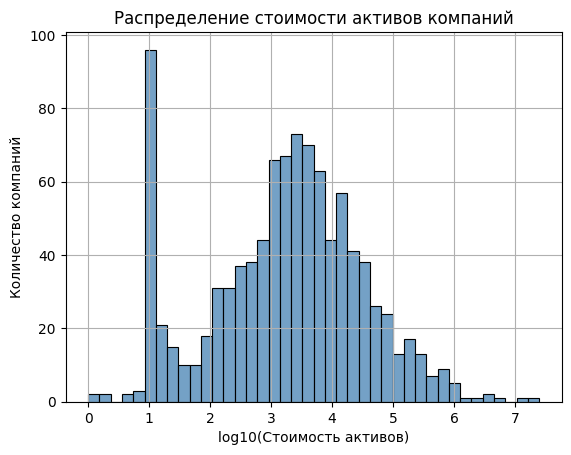

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


assets = df["B_assets"].dropna()
assets = assets[assets > 0]
log_assets = np.log10(assets)
plt.figure()
sns.histplot(log_assets, bins=40, color="steelblue")
plt.title("Распределение стоимости активов компаний")
plt.xlabel("log10(Стоимость активов)")
plt.ylabel("Количество компаний")
plt.grid()

In [58]:
small_assets = df[df["B_assets"] <= 20]
print(f"Companies with small assets {len(small_assets)}")
print(f"Freq", small_assets["B_assets"].value_counts().sort_index())

Companies with small assets 128
Freq B_assets
1.0      2
2.0      2
4.0      1
5.0      1
6.0      1
7.0      1
8.0      1
9.0      2
10.0    82
11.0     6
12.0     6
13.0     1
14.0     1
15.0     5
17.0     2
18.0    12
20.0     2
Name: count, dtype: int64


## То есть наибольшее число компаний с 10к, что соответствует наименьшему уставному капиталу в РФ 10к, проверим это

In [59]:

df_10 = df[df["B_assets"] == 10]
print("Количество компаний:", len(df_10))
print("\nРаспределение собственного капитала:")
print(df_10["B_total_equity"].value_counts(dropna=False))
print("\nРаспределение краткосрочных обязательств:")
print(df_10["B_shortterm_liab"].value_counts(dropna=False))


Количество компаний: 82

Распределение собственного капитала:
B_total_equity
 10.0    75
 NaN      2
 8.0      1
 9.0      1
-28.0     1
 4.0      1
-9.0      1
Name: count, dtype: int64

Распределение краткосрочных обязательств:
B_shortterm_liab
NaN     75
10.0     2
2.0      1
1.0      1
38.0     1
6.0      1
18.0     1
Name: count, dtype: int64


In [60]:

for col in ["PL_revenue", "PL_net_profit"]:
    print(f"\n{col}")
    print("Пропущено:", df_10[col].isna().sum())
    print("Равно нулю:", (df_10[col] == 0).sum())
    print("Ненулевых значений:", (
        df_10[col].notna() & (df_10[col] != 0)
    ).sum())



PL_revenue
Пропущено: 80
Равно нулю: 0
Ненулевых значений: 2

PL_net_profit
Пропущено: 78
Равно нулю: 1
Ненулевых значений: 3


## То есть значительное число компаний зарегистрированных для каких то своих целей, имеющих минимальный уставной капитал и не проводящих активных действий (выручки и прибыли)

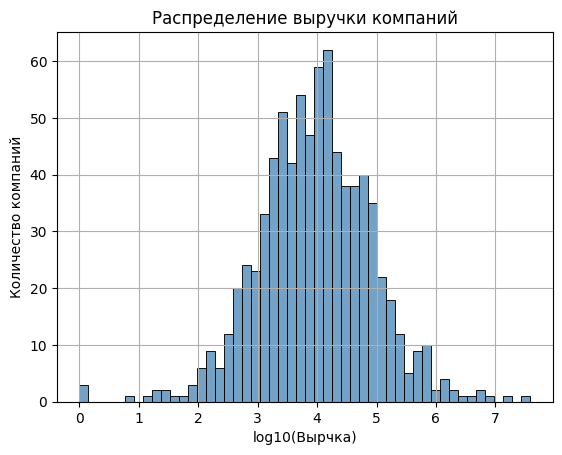

In [62]:
revenue = df["PL_revenue"].dropna()
revenue = revenue[revenue > 0]
log_revenue = np.log10(revenue)
plt.figure()
sns.histplot(log_revenue, bins = 50, color = "steelblue")
plt.title("Распределение выручки компаний")
plt.xlabel("log10(Выручка)")
plt.ylabel("Количество компаний")
plt.grid()

## Можно увидеть, что явных аномалий нет, большинство лежит в пределах 3-5, то есть выручка 1к-100к, есть заметные количества компаний с выручками выше 10млн, которые существенно влияют на среднее. Пик районе 10к соответсвует медиане 9800.

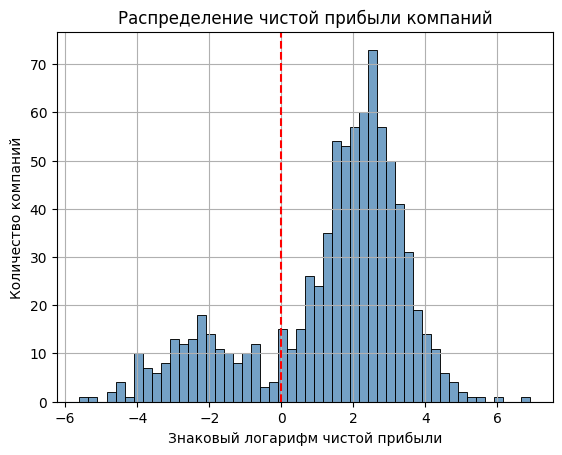

In [64]:

# Убираем пропуски, сохраняя отрицательные значения и нули
profit = df["PL_net_profit"].dropna()

log_profit = np.sign(profit) * np.log10(1 + np.abs(profit))
plt.figure()
plt.axvline(0, color="red", linestyle="--", label="Нулевая прибыль")
sns.histplot(log_profit, bins = 50, color = "steelblue")
plt.title("Распределение чистой прибыли компаний")
plt.xlabel("Знаковый логарифм чистой прибыли")
plt.ylabel("Количество компаний")
plt.grid()

In [65]:
profit = df["PL_net_profit"].dropna()

profitable = (profit > 0).sum()
unprofitable = (profit < 0).sum()
zero_profit = (profit == 0).sum()

total = len(profit)

print(f"Прибыльных компаний: {profitable} ({profitable/total*100:.1f}%)")
print(f"Убыточных компаний: {unprofitable} ({unprofitable/total*100:.1f}%)")
print(f"С нулевой прибылью: {zero_profit} ({zero_profit/total*100:.1f}%)")
print(f"Нет данных о прибыли: {df['PL_net_profit'].isna().sum()}")

Прибыльных компаний: 647 (78.0%)
Убыточных компаний: 168 (20.2%)
С нулевой прибылью: 15 (1.8%)
Нет данных о прибыли: 170


## График с чистой прибылью показывает, что заметная часть компаний (20.2% является убыточной). Медианное значение прибыли находится около пика 3, т.е. 1000, также есть заметное число как краней прибыльных компаний >1млн, так и убыточных >0.1 млн убытков. 1.8% компаний имеют нулевую прибыль. 

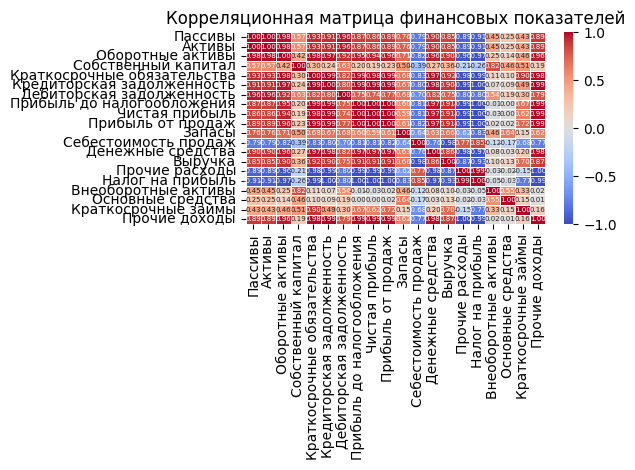

In [79]:

corr = df.corr(method="pearson")


ru_names = {
    "B_liab": "Пассивы",
    "B_assets": "Активы",
    "B_current_assets": "Оборотные активы",
    "B_total_equity": "Собственный капитал",
    "B_shortterm_liab": "Краткосрочные обязательства",
    "B_shortterm_payables": "Кредиторская задолженность",
    "B_accounts_receivable": "Дебиторская задолженность",
    "PL_before_tax": "Прибыль до налогообложения",
    "PL_net_profit": "Чистая прибыль",
    "PL_profit_from_sales": "Прибыль от продаж",
    "B_inventories": "Запасы",
    "PL_cost_of_sales": "Себестоимость продаж",
    "B_cash_equivalents": "Денежные средства",
    "PL_revenue": "Выручка",
    "PL_other_expenses": "Прочие расходы",
    "PL_income_tax": "Налог на прибыль",
    "B_noncurrent_assets": "Внеоборотные активы",
    "B_fixed_assets": "Основные средства",
    "B_shortterm_debt": "Краткосрочные займы",
    "PL_other_income": "Прочие доходы"
}

# Переименовываем строки и столбцы матрицы
corr_ru = corr.rename(
    index=ru_names,
    columns=ru_names
)


plt.figure()
sns.heatmap(corr_ru, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 5})
plt.title("Корреляционная матрица финансовых показателей")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()


In [80]:

mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().reset_index()
pairs.columns = ["Показатель 1", "Показатель 2", "Корреляция"]
pairs["abs_corr"] = pairs["Корреляция"].abs()
pairs = pairs.sort_values("abs_corr", ascending=False)
pairs["Показатель 1"] = pairs["Показатель 1"].replace(ru_names)
pairs["Показатель 2"] = pairs["Показатель 2"].replace(ru_names)
display(pairs.head(15).round(4))

,Показатель 1,Показатель 2,Корреляция,abs_corr
0,Пассивы,Активы,1.0000,1.0000
179,Прочие расходы,Прочие доходы,-0.9999,0.9999
112,Прибыль до налогообложения,Чистая прибыль,0.9998,0.9998
140,Прибыль от продаж,Налог на прибыль,-0.9993,0.9993
113,Прибыль до налогообложения,Прибыль от продаж,0.9990,0.9990
124,Чистая прибыль,Прибыль от продаж,0.9983,0.9983
119,Прибыль до налогообложения,Налог на прибыль,-0.9978,0.9978
130,Чистая прибыль,Налог на прибыль,-0.9965,0.9965
94,Кредиторская задолженность,Налог на прибыль,-0.9954,0.9954
80,Краткосрочные обязательства,Налог на прибыль,-0.9946,0.9946


## Целый ряд параметров имеют корреляцию, а именно активы, пассивы, оборотные средства, что объясняется их схожим значением баланса компании. Краткосрочные обязательства, задолженности также ялвяются балансными характеристиками, как и чистая прибыль, прибыль от продаж и прибыль до налогообложения. Таким образом этот блок параметров имеют между собой прямую пропорциональную зависимость. Между собой также напрямую зависят прочие расходы и налог на прибыль. Доходы от расходов (что и логично). 

In [81]:
x = "PL_other_income"
y = "PL_other_expenses"
data = df[[x, y]].dropna()
print("Количество наблюдений:", len(data))
print("Корреляция Пирсона:",data[x].corr(data[y], method="pearson"))
print("Корреляция Спирмена:",data[x].corr(data[y], method="spearman"))

Количество наблюдений: 275
Корреляция Пирсона: -0.9998534021821661
Корреляция Спирмена: -0.7564522521383811


## Доходы от расходов не должны так напрямую зависеть, для проверки был проведено сравнение также корреляции Спирмена, которая позволяет уйти от сильного влияния абсолютных значений. Здесь она также сохраняется, но уже значительно менее явно, что говорит о серьезном вкладе этой корреляции для особо крупных компаний.

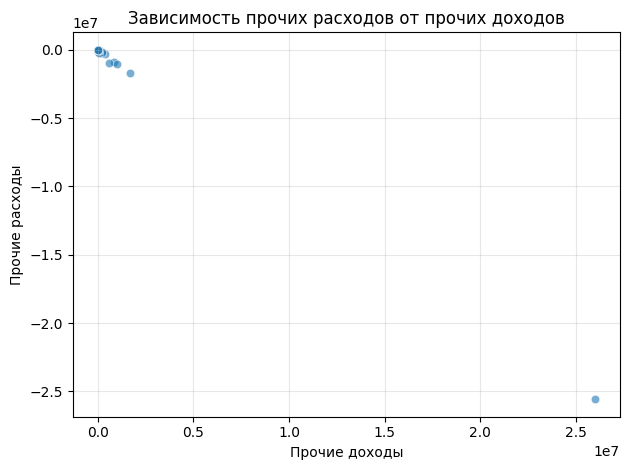

In [82]:

plt.figure()
sns.scatterplot(data=data,x="PL_other_income",y="PL_other_expenses",alpha=0.6)

plt.title("Зависимость прочих расходов от прочих доходов")
plt.xlabel("Прочие доходы")
plt.ylabel("Прочие расходы")
plt.grid(alpha=0.3)
plt.tight_layout()

In [84]:

r_before = data["PL_other_income"].corr( data["PL_other_expenses"] )
data_sorted = data.sort_values(by="PL_other_income",ascending=False)
data_without_outlier = data_sorted.iloc[10:]


r_after = data_without_outlier["PL_other_income"].corr(data_without_outlier["PL_other_expenses"] )

print(f"Корреляция до исключения: {r_before:.4f}")
print(f"Корреляция после исключения: {r_after:.4f}")
print(f"Количество наблюдений: {len(data_without_outlier)}")


Корреляция до исключения: -0.9999
Корреляция после исключения: -0.5929
Количество наблюдений: 265


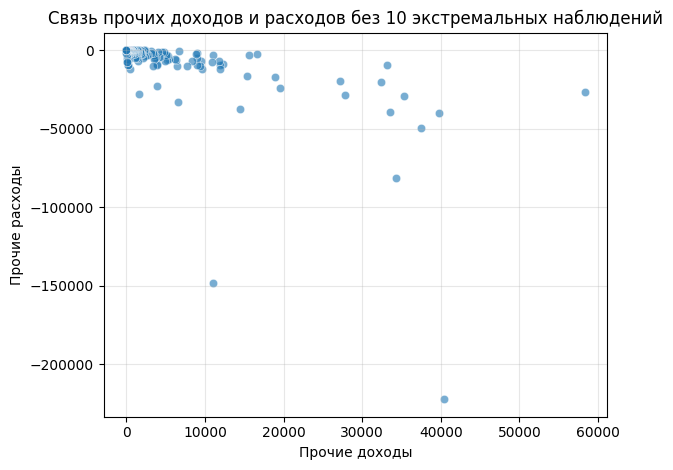

In [86]:

plt.figure()

sns.scatterplot(data=data_without_outlier, x="PL_other_income", y="PL_other_expenses",alpha=0.6)
plt.title("Связь прочих доходов и расходов без 10 экстремальных наблюдений")
plt.xlabel("Прочие доходы")
plt.ylabel("Прочие расходы")
plt.grid(alpha=0.3)
plt.tight_layout()


## Таким образом мы видим, что связь между прочими доходами и расходами не является такой сильной, как изначально показала матрица корреляции Пирсона. В частности, исключив 10 крупнешейших по доходам компаний, мы видим уже корреляцию не 0.99, а 0.59, то есть не настолько сильную. Исклювич 10 из 275 компаний мы получили немного иную картину, что говорит о существенном вкладе в анализ этих экстремальных значений и неустойчивости наблюдаемого явления корреляции.